# Relatório Técnico - Projeto Final: Biblioteca de Redes Neurais MLP

**INE5664 - Aprendizado de Máquina**<br/>
**Departamento de Informática e Estatística (INE/CTC/UFSC)**<br/>
**Professor:** Prof. Dr. Eduardo Camilo Inacio

---

### Identificação da Equipe

| Nome do Integrante | Matrícula |
| :--- | :--- |
| Lukas Dávila Resgalla | 23200519 |
| Leila Nunes dos Anjos | 23204361 |
| Giovanna Gomes Tonelli | 23205461 |

In [1]:
SEMENTE = 42

In [2]:
from sklearn.model_selection import train_test_split


def dividir_dados(X, y, semente, estratificar=False):
    """Divide em 70% treino, 15% validação e 15% teste."""
    estrato = y if estratificar else None
    X_treino, X_resto, y_treino, y_resto = train_test_split(
        X, y, test_size=0.30, random_state=semente, stratify=estrato
    )

    estrato = y_resto if estratificar else None
    X_val, X_teste, y_val, y_teste = train_test_split(
        X_resto, y_resto, test_size=0.50, random_state=semente, stratify=estrato
    )

    return X_treino, X_val, X_teste, y_treino, y_val, y_teste

In [3]:
from sklearn.preprocessing import StandardScaler


def padronizar(X_treino, X_val, X_teste):
    """Padroniza os dados usando média e desvio calculados só no treino."""
    escalador = StandardScaler()
    X_treino = escalador.fit_transform(X_treino)
    X_val = escalador.transform(X_val)
    X_teste = escalador.transform(X_teste)
    return X_treino, X_val, X_teste

In [4]:
import matplotlib.pyplot as plt


def plotar_curvas(historico, titulo):
    """Plota o custo de treino e o de validação ao longo das épocas."""
    plt.plot(historico["custo_treino"], label="Treino")
    if historico["custo_validacao"]:
        plt.plot(historico["custo_validacao"], label="Validação")
    plt.xlabel("Época")
    plt.ylabel("Custo")
    plt.title(titulo)
    plt.legend()
    plt.show()

## Regressão

Nesta seção usamos o dataset **Diabetes** do scikit-learn: 442 pacientes, 10 características (idade, sexo, IMC, pressão e medidas de sangue) e, como alvo, um número que mede a progressão da doença um ano depois. É um problema de **regressão**, porque o alvo é um valor contínuo.

Passos: dividir os dados em 70% treino, 15% validação e 15% teste; padronizar `X` e `y` usando só o treino; treinar uma rede com a nossa biblioteca `mlp/`; e avaliar no teste, depois de converter a previsão de volta à escala original.

In [5]:
from sklearn.datasets import load_diabetes

dados = load_diabetes()
X = dados.data
y = dados.target

print("X:", X.shape)
print("y:", y.shape)

X: (442, 10)
y: (442,)


In [6]:
y = y.reshape(-1, 1)

X_treino, X_val, X_teste, y_treino, y_val, y_teste = dividir_dados(
    X, y, SEMENTE
)

print("Treino:", X_treino.shape, y_treino.shape)
print("Validação:", X_val.shape, y_val.shape)
print("Teste:", X_teste.shape, y_teste.shape)

Treino: (309, 10) (309, 1)
Validação: (66, 10) (66, 1)
Teste: (67, 10) (67, 1)


In [7]:
X_treino, X_val, X_teste = padronizar(X_treino, X_val, X_teste)

escalador_y = StandardScaler()
y_treino = escalador_y.fit_transform(y_treino)
y_val = escalador_y.transform(y_val)
y_teste_original = y_teste
y_teste = escalador_y.transform(y_teste)

print("X treino: média", X_treino.mean().round(3), "desvio", X_treino.std().round(3))
print("y treino: média", y_treino.mean().round(3), "desvio", y_treino.std().round(3))

X treino: média 0.0 desvio 1.0
y treino: média -0.0 desvio 1.0


In [8]:
from mlp.rede import RedeNeural
from mlp.camadas import Densa
from mlp.ativacoes import ReLU
from mlp.inicializadores import He
from mlp.custos import MSE

rede = RedeNeural(semente_aleatoria=SEMENTE)
rede.adicionar(Densa(10, 16, inicializador=He(), gerador_aleatorio=rede.gerador_aleatorio))
rede.adicionar(ReLU())
rede.adicionar(Densa(16, 8, inicializador=He(), gerador_aleatorio=rede.gerador_aleatorio))
rede.adicionar(ReLU())
rede.adicionar(Densa(8, 1, gerador_aleatorio=rede.gerador_aleatorio))
rede.compilar(MSE())

print("Camadas:", len(rede.camadas))
print("Saída para 3 exemplos:", rede.predizer(X_treino[:3]).shape)

Camadas: 5
Saída para 3 exemplos: (3, 1)


Época 10/200 - custo_treino: 0.594513 - custo_validacao: 0.598476
Época 20/200 - custo_treino: 0.508493 - custo_validacao: 0.567632
Época 30/200 - custo_treino: 0.469760 - custo_validacao: 0.543867
Época 40/200 - custo_treino: 0.446510 - custo_validacao: 0.530087
Época 50/200 - custo_treino: 0.431059 - custo_validacao: 0.521883
Época 60/200 - custo_treino: 0.418839 - custo_validacao: 0.533458
Época 70/200 - custo_treino: 0.408600 - custo_validacao: 0.531388
Época 80/200 - custo_treino: 0.400183 - custo_validacao: 0.539205
Época 90/200 - custo_treino: 0.391938 - custo_validacao: 0.534152
Época 100/200 - custo_treino: 0.386855 - custo_validacao: 0.543856
Época 110/200 - custo_treino: 0.386664 - custo_validacao: 0.512436
Época 120/200 - custo_treino: 0.373837 - custo_validacao: 0.524157
Época 130/200 - custo_treino: 0.369281 - custo_validacao: 0.550508
Época 140/200 - custo_treino: 0.361312 - custo_validacao: 0.528030
Época 150/200 - custo_treino: 0.355825 - custo_validacao: 0.532377
Époc

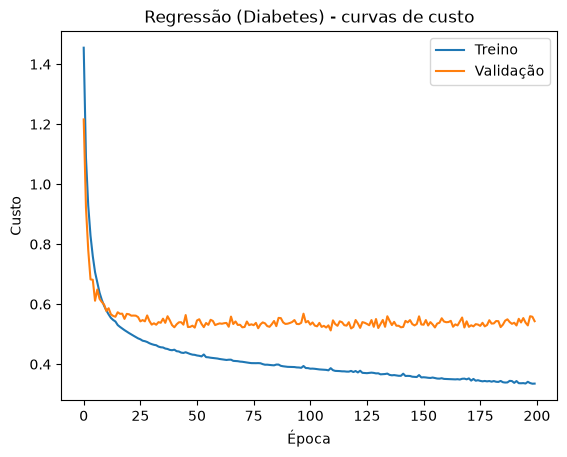

In [9]:
historico = rede.treinar(
    X_treino,
    y_treino,
    epocas=200,
    taxa_aprendizagem=0.01,
    tamanho_lote=32,
    X_validacao=X_val,
    y_validacao=y_val,
    verbal=True,
)

plotar_curvas(historico, "Regressão (Diabetes) - curvas de custo")

In [10]:
import numpy as np

previsao_padronizada = rede.predizer(X_teste)
previsao = escalador_y.inverse_transform(previsao_padronizada)

erro = previsao - y_teste_original
mae = np.mean(np.abs(erro))
mse = np.mean(erro ** 2)
rmse = np.sqrt(mse)

# Referência: um modelo que sempre prevê a média do y de treino
rmse_referencia = np.sqrt(np.mean((y_teste_original - escalador_y.mean_) ** 2))

print(f"MAE:  {mae:.2f}")
print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"RMSE da referência (prever a média): {rmse_referencia:.2f}")

MAE:  50.39
MSE:  3652.92
RMSE: 60.44
RMSE da referência (prever a média): 75.54


### Análise dos resultados

Usamos uma rede com duas camadas escondidas (16 e 8 neurônios, ReLU, inicialização He) e uma saída linear de um neurônio, já que o alvo é um número contínuo. O treino foi com MSE, taxa de aprendizagem 0,01, lotes de 32 e 200 épocas, com semente 42.

Nas curvas, o custo de treino desce até o fim, enquanto o de validação cai rápido e se estabiliza em torno de 0,52 a 0,57 já nas primeiras 20 ou 30 épocas, e dali em diante só oscila. O ponto mais baixo, cerca de 0,51, aparece por volta da época 110, mas parece mais flutuação do que melhora de verdade. A rede segue se ajustando ao treino sem ganhar nada na validação, ou seja, começou a decorar um pouco. Vale lembrar que esses custos estão na escala padronizada do `y`.

No teste, já na escala original, o MAE ficou em cerca de 50 e o RMSE em cerca de 60. Para ter uma noção do que isso significa, um modelo que sempre chuta a média do treino tem RMSE perto de 75. A rede aprendeu alguma coisa, mas a melhora não é grande. Não chega a ser surpresa: são só 442 pacientes e os dados têm bastante ruído.

Os hiperparâmetros foram escolhidos de forma simples, olhando treino e validação. O teste só foi usado no final, uma única vez. Com mais tempo, testaríamos parar o treino perto das primeiras épocas de platô da validação, uma rede menor e outras taxas de aprendizagem.

## Classificação Binária

Nesta seção usamos o dataset **Breast Cancer** do scikit-learn: 569 pacientes, 30 características numéricas medidas em imagens de tumores e, como alvo, a classe do tumor (0 = maligno, 1 = benigno). É um problema de **classificação binária**.

Passos: dividir os dados de forma **estratificada** em 70% treino, 15% validação e 15% teste (mantendo a proporção das classes); padronizar só o `X` usando o treino (o `y` já é 0/1); treinar uma rede com a nossa biblioteca `mlp/`, com Sigmoid na saída e entropia cruzada binária como custo; e avaliar no teste com acurácia, precisão, revocação e F1-score.

In [11]:
from sklearn.datasets import load_breast_cancer

dados = load_breast_cancer()
X = dados.data
y = dados.target

print("X:", X.shape)
print("y:", y.shape)
print("Quantidade por classe (0 e 1):", np.bincount(y))

X: (569, 30)
y: (569,)
Quantidade por classe (0 e 1): [212 357]


In [12]:
X_treino, X_val, X_teste, y_treino, y_val, y_teste = dividir_dados(
    X, y, SEMENTE, estratificar=True
)

y_treino = y_treino.reshape(-1, 1)
y_val = y_val.reshape(-1, 1)
y_teste = y_teste.reshape(-1, 1)

print("Treino:", X_treino.shape, y_treino.shape, "- proporção da classe 1:", y_treino.mean().round(3))
print("Validação:", X_val.shape, y_val.shape, "- proporção da classe 1:", y_val.mean().round(3))
print("Teste:", X_teste.shape, y_teste.shape, "- proporção da classe 1:", y_teste.mean().round(3))

Treino: (398, 30) (398, 1) - proporção da classe 1: 0.628
Validação: (85, 30) (85, 1) - proporção da classe 1: 0.624
Teste: (86, 30) (86, 1) - proporção da classe 1: 0.628


In [13]:
X_treino, X_val, X_teste = padronizar(X_treino, X_val, X_teste)

print("X treino: média", X_treino.mean().round(3), "desvio", X_treino.std().round(3))

X treino: média -0.0 desvio 1.0


In [14]:
from mlp.ativacoes import Sigmoid
from mlp.custos import EntropiaCruzadaBinaria

rede = RedeNeural(semente_aleatoria=SEMENTE)
rede.adicionar(Densa(30, 16, inicializador=He(), gerador_aleatorio=rede.gerador_aleatorio))
rede.adicionar(ReLU())
rede.adicionar(Densa(16, 8, inicializador=He(), gerador_aleatorio=rede.gerador_aleatorio))
rede.adicionar(ReLU())
rede.adicionar(Densa(8, 1, gerador_aleatorio=rede.gerador_aleatorio))
rede.adicionar(Sigmoid())
rede.compilar(EntropiaCruzadaBinaria())

print("Camadas:", len(rede.camadas))
print("Saída para 3 exemplos:", rede.predizer(X_treino[:3]).shape)

Camadas: 6
Saída para 3 exemplos: (3, 1)


Época 10/100 - custo_treino: 0.075884 - custo_validacao: 0.104206
Época 20/100 - custo_treino: 0.047643 - custo_validacao: 0.081931
Época 30/100 - custo_treino: 0.032909 - custo_validacao: 0.083492
Época 40/100 - custo_treino: 0.022527 - custo_validacao: 0.073804
Época 50/100 - custo_treino: 0.016877 - custo_validacao: 0.067190
Época 60/100 - custo_treino: 0.013239 - custo_validacao: 0.066263
Época 70/100 - custo_treino: 0.010823 - custo_validacao: 0.063358
Época 80/100 - custo_treino: 0.008933 - custo_validacao: 0.061638
Época 90/100 - custo_treino: 0.007446 - custo_validacao: 0.060966
Época 100/100 - custo_treino: 0.006316 - custo_validacao: 0.061171


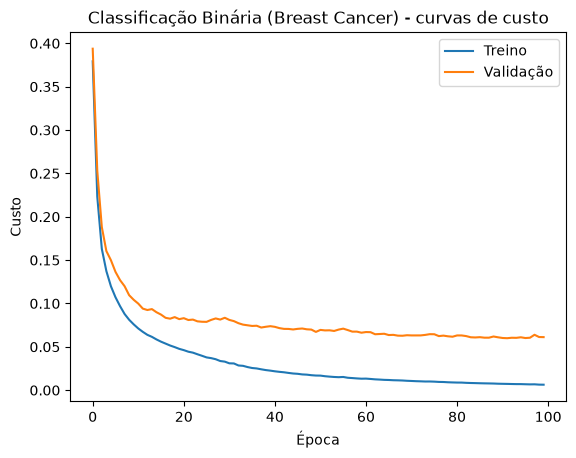

In [15]:
historico = rede.treinar(
    X_treino,
    y_treino,
    epocas=100,
    taxa_aprendizagem=0.1,
    tamanho_lote=32,
    X_validacao=X_val,
    y_validacao=y_val,
    verbal=True,
)

plotar_curvas(historico, "Classificação Binária (Breast Cancer) - curvas de custo")

In [16]:
probabilidades = rede.predizer(X_teste)
previsao = (probabilidades >= 0.5).astype(int)

# Classe positiva = 1 (benigno)
vp = np.sum((previsao == 1) & (y_teste == 1))
vn = np.sum((previsao == 0) & (y_teste == 0))
fp = np.sum((previsao == 1) & (y_teste == 0))
fn = np.sum((previsao == 0) & (y_teste == 1))

acuracia = (vp + vn) / len(y_teste)
precisao = vp / (vp + fp)
revocacao = vp / (vp + fn)
f1 = 2 * precisao * revocacao / (precisao + revocacao)

print(f"Acurácia:  {acuracia:.4f}")
print(f"Precisão:  {precisao:.4f}")
print(f"Revocação: {revocacao:.4f}")
print(f"F1-score:  {f1:.4f}")

Acurácia:  0.9535
Precisão:  0.9808
Revocação: 0.9444
F1-score:  0.9623


### Análise dos resultados

A rede tem 30 entradas, duas camadas escondidas (16 e 8 neurônios, ReLU, He) e um neurônio de saída com Sigmoid, que dá a probabilidade de a classe ser 1. Usamos entropia cruzada binária, lotes de 32, 100 épocas e semente 42. Para a taxa de aprendizagem, comparamos 0,01, 0,05 e 0,1 pelo custo de validação e ficamos com 0,1, que teve o menor valor (cerca de 0,06).

O custo de treino foi até perto de 0,006, e o de validação estabilizou em torno de 0,06 nas últimas épocas, sem voltar a subir. Existe uma distância entre as duas curvas, mas nada fora do esperado, e não apareceu overfitting forte nessas 100 épocas.

Para classificar, a probabilidade a partir de 0,5 vira classe 1 (benigno, que é a classe positiva). No teste, com 86 exemplos, deu acurácia de cerca de 95%, precisão de 98%, revocação de 94% e F1 de 96%, o que dá uns 4 erros. A precisão responde, entre os casos que a rede chamou de benignos, quantos eram mesmo benignos. A revocação responde, entre os benignos de verdade, quantos ela encontrou. Num problema de saúde, o erro mais grave é chamar um tumor maligno de benigno, e é esse tipo de erro que derruba a precisão.

O teste é pequeno, e cada erro mexe mais de 1 ponto percentual nas métricas, então diferenças pequenas entre configurações não dizem muita coisa. A divisão foi estratificada (cerca de 63% de benignos nos três conjuntos) e o teste foi usado uma vez só. Ficou como ideia repetir com outras sementes e testar parada antecipada.

## Classificação Multiclasse

Nesta seção usamos o dataset **Wine** do scikit-learn: 178 vinhos, 13 características químicas (como álcool, acidez e fenóis) e, como alvo, o tipo do vinho, com 3 classes. É um problema de **classificação multiclasse**.

Passos: dividir os dados de forma **estratificada** em 70% treino, 15% validação e 15% teste, usando os rótulos como números; converter os rótulos para *one-hot* só depois da divisão; padronizar só o `X` usando o treino; treinar uma rede com a nossa biblioteca `mlp/`, com Softmax na saída e entropia cruzada categórica como custo; e avaliar no teste com a matriz de confusão e as métricas acurácia, precisão, revocação e F1-score (média macro).

In [17]:
from sklearn.datasets import load_wine

dados = load_wine()
X = dados.data
y = dados.target

print("X:", X.shape)
print("y:", y.shape)
print("Classes:", dados.target_names.tolist())
print("Quantidade por classe:", np.bincount(y))

X: (178, 13)
y: (178,)
Classes: ['class_0', 'class_1', 'class_2']
Quantidade por classe: [59 71 48]


In [18]:
# Divisão com os rótulos como números (0, 1, 2), que é o que o stratify precisa
X_treino, X_val, X_teste, y_treino, y_val, y_teste = dividir_dados(
    X, y, SEMENTE, estratificar=True
)

# Rótulos do teste guardados como números, para a matriz de confusão
classes_teste = y_teste

# Só agora converte para one-hot: classe 2 vira [0, 1, 0] etc.
num_classes = 3
y_treino = np.eye(num_classes)[y_treino]
y_val = np.eye(num_classes)[y_val]
y_teste = np.eye(num_classes)[y_teste]

print("Treino:", X_treino.shape, y_treino.shape)
print("Validação:", X_val.shape, y_val.shape)
print("Teste:", X_teste.shape, y_teste.shape)
print("Exemplos por classe no teste:", np.bincount(classes_teste))

Treino: (124, 13) (124, 3)
Validação: (27, 13) (27, 3)
Teste: (27, 13) (27, 3)
Exemplos por classe no teste: [ 9 11  7]


In [19]:
X_treino, X_val, X_teste = padronizar(X_treino, X_val, X_teste)

print("X treino: média", X_treino.mean().round(3), "desvio", X_treino.std().round(3))

X treino: média 0.0 desvio 1.0


In [20]:
from mlp.ativacoes import Softmax
from mlp.custos import EntropiaCruzadaCategorica

rede = RedeNeural(semente_aleatoria=SEMENTE)
rede.adicionar(Densa(13, 16, inicializador=He(), gerador_aleatorio=rede.gerador_aleatorio))
rede.adicionar(ReLU())
rede.adicionar(Densa(16, 8, inicializador=He(), gerador_aleatorio=rede.gerador_aleatorio))
rede.adicionar(ReLU())
rede.adicionar(Densa(8, num_classes, gerador_aleatorio=rede.gerador_aleatorio))
rede.adicionar(Softmax())
rede.compilar(EntropiaCruzadaCategorica())

print("Camadas:", len(rede.camadas))
print("Saída para 3 exemplos:", rede.predizer(X_treino[:3]).shape)
print("Soma das probabilidades de cada exemplo:", rede.predizer(X_treino[:3]).sum(axis=1))

Camadas: 6
Saída para 3 exemplos: (3, 3)
Soma das probabilidades de cada exemplo: [1. 1. 1.]


Época 10/100 - custo_treino: 0.926157 - custo_validacao: 0.857375
Época 20/100 - custo_treino: 0.678393 - custo_validacao: 0.627717
Época 30/100 - custo_treino: 0.526424 - custo_validacao: 0.499095
Época 40/100 - custo_treino: 0.398350 - custo_validacao: 0.399343
Época 50/100 - custo_treino: 0.302244 - custo_validacao: 0.324631
Época 60/100 - custo_treino: 0.224907 - custo_validacao: 0.260722
Época 70/100 - custo_treino: 0.164940 - custo_validacao: 0.210629
Época 80/100 - custo_treino: 0.123757 - custo_validacao: 0.179069
Época 90/100 - custo_treino: 0.096892 - custo_validacao: 0.159606
Época 100/100 - custo_treino: 0.078448 - custo_validacao: 0.146664


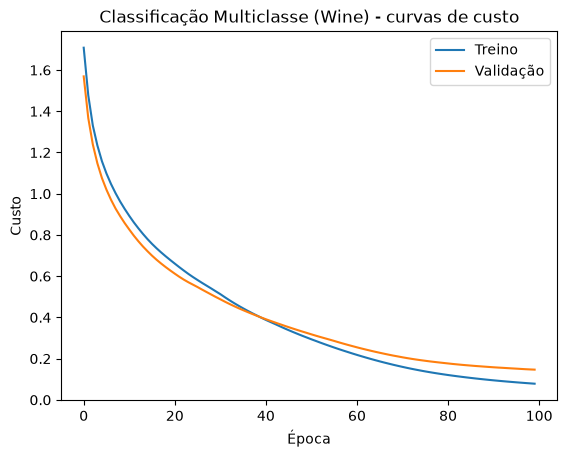

In [21]:
historico = rede.treinar(
    X_treino,
    y_treino,
    epocas=100,
    taxa_aprendizagem=0.01,
    tamanho_lote=16,
    X_validacao=X_val,
    y_validacao=y_val,
    verbal=True,
)

plotar_curvas(historico, "Classificação Multiclasse (Wine) - curvas de custo")

In [22]:
probabilidades = rede.predizer(X_teste)
previsao = np.argmax(probabilidades, axis=1)

# matriz[i, j] = quantos exemplos da classe real i foram previstos como classe j
matriz = np.zeros((num_classes, num_classes), dtype=int)
for real, predita in zip(classes_teste, previsao):
    matriz[real, predita] += 1

acertos = np.diag(matriz)
acuracia = acertos.sum() / matriz.sum()
precisao_por_classe = acertos / matriz.sum(axis=0)
revocacao_por_classe = acertos / matriz.sum(axis=1)
f1_por_classe = (
    2 * precisao_por_classe * revocacao_por_classe
    / (precisao_por_classe + revocacao_por_classe)
)

print("Matriz de confusão (linhas = real, colunas = previsto):")
print(matriz)
print()
print(f"Acurácia:           {acuracia:.4f}")
print(f"Precisão (macro):   {precisao_por_classe.mean():.4f}")
print(f"Revocação (macro):  {revocacao_por_classe.mean():.4f}")
print(f"F1-score (macro):   {f1_por_classe.mean():.4f}")
print()
print("Por classe (precisão, revocação, F1):")
for i, nome in enumerate(dados.target_names):
    print(f"  {nome}: {precisao_por_classe[i]:.4f}, {revocacao_por_classe[i]:.4f}, {f1_por_classe[i]:.4f}")

Matriz de confusão (linhas = real, colunas = previsto):
[[ 9  0  0]
 [ 0 11  0]
 [ 0  0  7]]

Acurácia:           1.0000
Precisão (macro):   1.0000
Revocação (macro):  1.0000
F1-score (macro):   1.0000

Por classe (precisão, revocação, F1):
  class_0: 1.0000, 1.0000, 1.0000
  class_1: 1.0000, 1.0000, 1.0000
  class_2: 1.0000, 1.0000, 1.0000


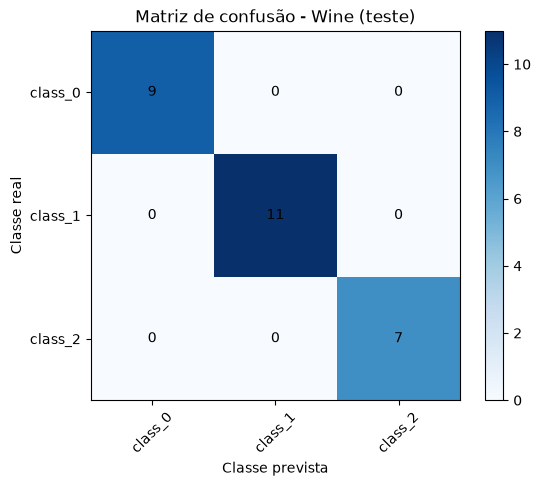

In [23]:
plt.imshow(matriz, cmap="Blues")
for real in range(num_classes):
    for predita in range(num_classes):
        plt.text(predita, real, matriz[real, predita], ha="center", va="center")
plt.xticks(range(num_classes), dados.target_names, rotation=45)
plt.yticks(range(num_classes), dados.target_names)
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.title("Matriz de confusão - Wine (teste)")
plt.colorbar()
plt.show()

### Análise dos resultados

Aqui a rede tem 13 entradas, camadas escondidas de 16 e 8 neurônios (ReLU, He) e 3 neurônios na saída com Softmax, que transforma as saídas em probabilidades que somam 1. A classe prevista é a de maior probabilidade. O custo é a entropia cruzada categórica, com lotes de 16, 100 épocas e semente 42.

Um detalhe do preparo dos dados: dividimos com os rótulos como números (0, 1, 2), porque o `stratify` precisa disso, e só depois convertemos para one-hot (a classe 1 vira `[0, 1, 0]`), que é o formato esperado pelo custo e pela Softmax.

Sobre a taxa de aprendizagem, comparamos 0,01, 0,05 e 0,1 na validação. Com 0,05 e 0,1 o custo de validação chegava ao mínimo cedo (épocas 36 e 17) e depois subia, que é overfitting. Com 0,01 ele caiu até o fim, e foi a que usamos. Nas curvas finais, treino e validação terminam perto de 0,08 e 0,15, ainda caindo, então daria para treinar mais.

No teste, a rede acertou os 27 exemplos: acurácia, precisão, revocação e F1 de 1,0 (os três últimos em média macro, calculados por classe e depois com média simples). Na matriz de confusão, onde a linha é a classe real e a coluna é a prevista, só a diagonal tem valores.

Esse 100% pede cautela. O teste tem só 27 exemplos (9, 11 e 7 por classe), e um único erro já baixaria a acurácia para cerca de 96%. Além disso, o Wine é um dataset fácil, com classes bem separadas depois da padronização, então o resultado não quer dizer que a rede seria perfeita com dados novos. O teste foi usado uma vez só. Para ter uma estimativa mais estável, o ideal seria repetir com outras sementes e divisões ou usar validação cruzada.

## Desafios e Aprendizados

Os três experimentos seguiram o mesmo caminho (dividir, padronizar, treinar, avaliar), mas cada um mostrou um cuidado diferente. Os principais estão abaixo.

**O formato dos dados importa.** Na regressão, o `y` do dataset Diabetes vem como uma lista simples, de formato `(m,)`, enquanto a saída da rede tem formato `(m, 1)`. Se os dois entram na conta do MSE assim, o NumPy combina os dois formatos em uma matriz `m x m` sem dar erro, e o custo sai errado. Foi preciso converter com `reshape(-1, 1)`. Na multiclasse aconteceu o contrário: o `stratify` do `train_test_split` precisa dos rótulos como números, então a divisão tem que vir antes de transformar o `y` em one-hot.

**Evitar vazamento de dados.** A média e o desvio da padronização são calculados só com o treino e depois aplicados na validação e no teste. Na regressão isso valeu também para o `y`, e as métricas MAE, MSE e RMSE só foram calculadas depois de voltar a previsão para a escala original com `inverse_transform`. Antes disso, os erros estariam em uma escala sem sentido.

**A taxa de aprendizagem muda o comportamento da mesma rede.** Na classificação binária, 0,1 deu o menor custo de validação. No Wine, taxas de 0,05 e 0,1 levavam o custo de validação a um mínimo cedo e depois ele subia, e só 0,01 deixou a curva caindo até o fim. Olhar as duas curvas juntas foi o que permitiu perceber isso, e a escolha foi sempre feita pela validação, sem consultar o teste.

**Conjuntos de teste pequenos enganam.** Com 27 exemplos no Wine, o resultado de 100% não prova que a rede é perfeita, porque um único erro já mudaria a acurácia. Com 86 exemplos na binária, cada erro vale mais de 1 ponto percentual. O resultado do teste é uma estimativa, e dá para confiar mais nela quando o conjunto é maior ou quando se repete o experimento.